# RQ1 — LLM–human agreement and the effect of input representation

**Question:** How well does the LLM agree with human ground truth overall, and to what extent does input representation (image vs text) affect that agreement?

**Design:**
- Compare LLM binary judgments (`llm_label`) against the human binary ground truth (`gt_label`) on the join key `(Diagram_ID, Criterion, Guideline)`.
- Representation: `image = PNG`, `text = SVG | XML`.
- Both models (ChatGPT + Claude) are **pooled** within each representation.
- Positive class for precision/recall/F1 is `1` (positive evaluation).
- 95% confidence intervals via **bootstrap** (10000 resamples) for precision, recall and F1.
- Image-vs-text difference assessed via a bootstrap CI of the difference.

> The binarized ground truth (`ground_truth_binary.csv`) is produced by `../ground-truth/build_ground_truth.ipynb` after the 12 boundary cases are decided. If that file is missing, this notebook runs in a clearly flagged **DRY-RUN** mode (boundary mean=2.5 mapped to 1) only to validate the code; dry-run results are **not** saved."

## 1. Setup and data loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import analysis_utils as au

NOTEBOOK_DIR = Path.cwd()
CSV_DIR = NOTEBOOK_DIR.parent  # analysis-csv
FIG_DIR = NOTEBOOK_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

EVAL_BINARY = CSV_DIR / "llm-evaluations" / "evaluations_binary.csv"
EVAL_ORDINAL = CSV_DIR / "llm-evaluations" / "evaluations_ordinal.csv"
GT_BINARY = CSV_DIR / "ground-truth" / "ground_truth_binary.csv"
GT_ORDINAL = CSV_DIR / "ground-truth" / "ground_truth_ordinal.csv"

OUT_SUMMARY = NOTEBOOK_DIR / "rq1_summary.csv"
OUT_OVERALL = NOTEBOOK_DIR / "rq1_overall_summary.csv"
OUT_ORDINAL = NOTEBOOK_DIR / "rq1_ordinal_agreement.csv"

assert EVAL_BINARY.exists(), f"Missing {EVAL_BINARY}"
print("OK - evaluations found:", EVAL_BINARY.name)

OK - evaluations found: evaluations_binary.csv


In [2]:
DRY_RUN = False

if GT_BINARY.exists():
    gt = pd.read_csv(GT_BINARY)
    assert "gt_label" in gt.columns, "ground_truth_binary.csv must have a gt_label column"
    print(f"OK - real binarized ground truth loaded ({len(gt)} rows)")
else:
    DRY_RUN = True
    print("=" * 78)
    print("DRY-RUN MODE: ground_truth_binary.csv not found.")
    print("Building a TEMPORARY in-memory binary GT from the ordinal means")
    print("(boundary mean == 2.5 mapped to 1) ONLY to validate the code path.")
    print("Results below are NOT saved. To produce the real analysis:")
    print("  1) fill BOUNDARY_DECISIONS in ../ground-truth/build_ground_truth.ipynb")
    print("  2) run that notebook to generate ground_truth_binary.csv")
    print("  3) re-run this notebook")
    print("=" * 78)
    gt_ord = pd.read_csv(GT_ORDINAL)
    gt = gt_ord[["Diagram_ID", "Criterion", "Guideline"]].copy()
    gt["gt_label"] = (gt_ord["gt_score_mean"] >= 2.5).astype(int)

gt = gt[["Diagram_ID", "Criterion", "Guideline", "gt_label"]]
gt.head()

OK - real binarized ground truth loaded (90 rows)


,Diagram_ID,Criterion,Guideline,gt_label
0,appwrite,accuracy,component_matching,1
1,appwrite,accuracy,interaction_matching,0
2,appwrite,clarity,element_identification,1
3,appwrite,clarity,reading_flow,0
4,appwrite,clarity,specific_symbology,0


## 2. Join LLM evaluations with the ground truth

Add the `Representation` column (image/text) and inner-join on `(Diagram_ID, Criterion, Guideline)`. The inner join automatically drops `sentry` (no ground truth) and keeps both models pooled.

In [3]:
evals = pd.read_csv(EVAL_BINARY)
evals["Representation"] = evals["Format"].apply(au.format_to_representation)

merged = evals.merge(gt, on=["Diagram_ID", "Criterion", "Guideline"], how="inner")

print(f"LLM evaluation rows: {len(evals)}")
print(f"Rows after inner-join with GT: {len(merged)}")
print(f"Diagrams in merged set: {sorted(merged['Diagram_ID'].unique())}")
print(f"Dropped diagrams (no GT): {sorted(set(evals['Diagram_ID']) - set(merged['Diagram_ID']))}")
print("\nItems per representation:")
print(merged["Representation"].value_counts().to_string())
merged.head()

LLM evaluation rows: 360
Rows after inner-join with GT: 360
Diagrams in merged set: ['appwrite', 'geoserver-cloud', 'magda-io', 'research-modifiability-pattern-experiment', 'sentry', 'spryker']
Dropped diagrams (no GT): []

Items per representation:
Representation
image    180
text     180


,Diagram_ID,Model,Format,Criterion,Guideline,llm_label,Representation,gt_label
0,appwrite,chatgpt,png,accuracy,component_matching,1,image,1
1,appwrite,chatgpt,png,accuracy,interaction_matching,1,image,0
2,appwrite,chatgpt,png,clarity,element_identification,1,image,1
3,appwrite,chatgpt,png,clarity,reading_flow,1,image,0
4,appwrite,chatgpt,png,clarity,specific_symbology,0,image,0


## 3. Overall classification metrics (binary, pooled - no representation split)

A basic, single-number view of how well the LLM matches the **binary** human ground truth across **all** items together (both representations and both models pooled):

- **Simple agreement** = fraction of items where `llm_label == gt_label` (raw agreement / accuracy).
- **Precision / recall / F1** (positive class = 1) and **macro-F1**, each with a bootstrap 95% CI.

> Chance-corrected agreement (Cohen's kappa) is reported in the next section on the **ordinal** scale, which is the more appropriate "agreement" measure. This section is binary because it is gated on the binarized GT (dry-run until the boundary decisions are filled).

In [4]:
N_BOOT = 10000
SEED = 42

yt_all = merged["gt_label"].to_numpy()
yp_all = merged["llm_label"].to_numpy()

overall = au.metrics(yt_all, yp_all)

# Bootstrap 95% CIs for the pooled precision/recall/F1.
overall_ci = {}
for mname, mfn in (("precision", au.precision), ("recall", au.recall), ("f1", au.f1)):
    overall_ci[mname] = au.bootstrap_ci(yt_all, yp_all, mfn, n_boot=N_BOOT, seed=SEED)

c_all = au.confusion(yt_all, yp_all)

print("Overall binary classification (pooled, all items - no representation split)")
print(f"  n items            : {overall['n']}")
print(f"  simple agreement   : {overall['accuracy']:.4f}  ({overall['accuracy']:.1%})")
print(f"  precision          : {overall_ci['precision'][0]:.4f}  "
      f"[{overall_ci['precision'][1]:.4f}, {overall_ci['precision'][2]:.4f}]")
print(f"  recall             : {overall_ci['recall'][0]:.4f}  "
      f"[{overall_ci['recall'][1]:.4f}, {overall_ci['recall'][2]:.4f}]")
print(f"  F1                 : {overall_ci['f1'][0]:.4f}  "
      f"[{overall_ci['f1'][1]:.4f}, {overall_ci['f1'][2]:.4f}]")
print(f"  macro-F1           : {overall['macro_f1']:.4f}")
print(f"\n  confusion (positive=1): TP={c_all.tp}, FP={c_all.fp}, FN={c_all.fn}, TN={c_all.tn}")

overall_summary = pd.DataFrame(
    [
        {"metric": "n", "value": overall["n"], "ci_lo": np.nan, "ci_hi": np.nan},
        {"metric": "agreement", "value": overall["accuracy"], "ci_lo": np.nan, "ci_hi": np.nan},
        {"metric": "precision", "value": overall_ci["precision"][0],
         "ci_lo": overall_ci["precision"][1], "ci_hi": overall_ci["precision"][2]},
        {"metric": "recall", "value": overall_ci["recall"][0],
         "ci_lo": overall_ci["recall"][1], "ci_hi": overall_ci["recall"][2]},
        {"metric": "f1", "value": overall_ci["f1"][0],
         "ci_lo": overall_ci["f1"][1], "ci_hi": overall_ci["f1"][2]},
        {"metric": "macro_f1", "value": overall["macro_f1"], "ci_lo": np.nan, "ci_hi": np.nan},
    ]
)
overall_summary.round(4)

Overall binary classification (pooled, all items - no representation split)
  n items            : 360
  simple agreement   : 0.7056  (70.6%)
  precision          : 0.7284  [0.6707, 0.7848]
  recall             : 0.7972  [0.7413, 0.8505]
  F1                 : 0.7613  [0.7146, 0.8035]
  macro-F1           : 0.6886

  confusion (positive=1): TP=169, FP=63, FN=43, TN=85


,metric,value,ci_lo,ci_hi
0,n,360.0000,NaN,NaN
1,agreement,0.7056,NaN,NaN
2,precision,0.7284,0.6707,0.7848
3,recall,0.7972,0.7413,0.8505
4,f1,0.7613,0.7146,0.8035
5,macro_f1,0.6886,NaN,NaN


## 4. Overall ordinal agreement (weighted Cohen's kappa)

This is the proper **ordinal** "agreement" between the LLM score and the human ground truth, computed on the original **1-4** scale (not binarized):

- LLM score: integer `1-4` (`evaluations_ordinal.csv`).
- Human GT: `gt_score_mean`, the mean of the 2 experts, which lands on half-steps `1.0, 1.5, ..., 4.0` (`ground_truth_ordinal.csv`).
- Categories use the full half-step grid so ordinal distances are correct (a 2.0-vs-2.5 disagreement counts as half of a 2.0-vs-3.0 disagreement).
- **Quadratic weighted kappa** (primary; penalizes large disagreements more) and **linear weighted kappa**, each with a bootstrap 95% CI.
- **Spearman's rho** is reported as a complementary rank-association measure (handles the fractional GT mean naturally).

> Unlike the binary sections, this runs on **real data right now** because the ordinal GT does not depend on the boundary decisions. Pooled over both representations and both models.

In [5]:
# Load ordinal LLM scores and ordinal GT, join on the same key, pool everything.
evals_ord = pd.read_csv(EVAL_ORDINAL)
gt_ord_full = pd.read_csv(GT_ORDINAL)

ord_merged = evals_ord.merge(
    gt_ord_full[["Diagram_ID", "Criterion", "Guideline", "gt_score_mean"]],
    on=["Diagram_ID", "Criterion", "Guideline"],
    how="inner",
)
print(f"Ordinal rows after join: {len(ord_merged)}  "
      f"(diagrams: {sorted(ord_merged['Diagram_ID'].unique())})")

gt_ord_vals = ord_merged["gt_score_mean"].to_numpy()
llm_ord_vals = ord_merged["score"].to_numpy()

GRID = au.ordinal_scale(1.0, 4.0, 0.5)  # [1.0, 1.5, ..., 4.0]

def _kappa_quad(a, b):
    return au.weighted_cohen_kappa(a, b, weights="quadratic", labels=GRID)

def _kappa_lin(a, b):
    return au.weighted_cohen_kappa(a, b, weights="linear", labels=GRID)

kq, kq_lo, kq_hi = au.bootstrap_ci(gt_ord_vals, llm_ord_vals, _kappa_quad, n_boot=N_BOOT, seed=SEED)
kl, kl_lo, kl_hi = au.bootstrap_ci(gt_ord_vals, llm_ord_vals, _kappa_lin, n_boot=N_BOOT, seed=SEED)
rho, rho_p = au.spearman_corr(gt_ord_vals, llm_ord_vals)
exact = float(np.mean(np.asarray(gt_ord_vals) == np.asarray(llm_ord_vals)))
within1 = float(np.mean(np.abs(np.asarray(gt_ord_vals) - np.asarray(llm_ord_vals)) <= 1.0))


def kappa_strength(k: float) -> str:
    if np.isnan(k):
        return "undefined"
    if k < 0:
        return "worse than chance"
    if k < 0.20:
        return "slight"
    if k < 0.40:
        return "fair"
    if k < 0.60:
        return "moderate"
    if k < 0.80:
        return "substantial"
    return "almost perfect"


print("\nOverall ORDINAL agreement (pooled, scale 1-4)")
print(f"  n items                       : {len(ord_merged)}")
print(f"  quadratic weighted kappa      : {kq:.4f}  [{kq_lo:.4f}, {kq_hi:.4f}]  ({kappa_strength(kq)})")
print(f"  linear weighted kappa         : {kl:.4f}  [{kl_lo:.4f}, {kl_hi:.4f}]  ({kappa_strength(kl)})")
print(f"  Spearman's rho                : {rho:.4f}  (p = {rho_p:.4g})")
print(f"  exact-match rate              : {exact:.4f}  ({exact:.1%})")
print(f"  within-1-point rate           : {within1:.4f}  ({within1:.1%})")

ordinal_summary = pd.DataFrame(
    [
        {"metric": "n", "value": len(ord_merged), "ci_lo": np.nan, "ci_hi": np.nan},
        {"metric": "weighted_kappa_quadratic", "value": kq, "ci_lo": kq_lo, "ci_hi": kq_hi},
        {"metric": "weighted_kappa_linear", "value": kl, "ci_lo": kl_lo, "ci_hi": kl_hi},
        {"metric": "spearman_rho", "value": rho, "ci_lo": np.nan, "ci_hi": np.nan},
        {"metric": "spearman_p", "value": rho_p, "ci_lo": np.nan, "ci_hi": np.nan},
        {"metric": "exact_match_rate", "value": exact, "ci_lo": np.nan, "ci_hi": np.nan},
        {"metric": "within_1_point_rate", "value": within1, "ci_lo": np.nan, "ci_hi": np.nan},
    ]
)
ordinal_summary.round(4)

Ordinal rows after join: 360  (diagrams: ['appwrite', 'geoserver-cloud', 'magda-io', 'research-modifiability-pattern-experiment', 'sentry', 'spryker'])



Overall ORDINAL agreement (pooled, scale 1-4)
  n items                       : 360
  quadratic weighted kappa      : 0.3077  [0.2168, 0.3932]  (fair)
  linear weighted kappa         : 0.2193  [0.1521, 0.2870]  (fair)
  Spearman's rho                : 0.3527  (p = 5.509e-12)
  exact-match rate              : 0.2611  (26.1%)
  within-1-point rate           : 0.8778  (87.8%)


,metric,value,ci_lo,ci_hi
0,n,360.0000,NaN,NaN
1,weighted_kappa_quadratic,0.3077,0.2168,0.3932
2,weighted_kappa_linear,0.2193,0.1521,0.2870
3,spearman_rho,0.3527,NaN,NaN
4,spearman_p,0.0000,NaN,NaN
5,exact_match_rate,0.2611,NaN,NaN
6,within_1_point_rate,0.8778,NaN,NaN


### 4.1 Agreement chart (quadratic weighted kappa)

Empirical boxplot: one value per diagram, grouped by representation. Bootstrap CIs are reported in text/CSV only (by-criterion chart is in RQ2).

In [6]:
ord_merged["Representation"] = ord_merged["Format"].apply(au.format_to_representation)

def kappa_ci(df: pd.DataFrame) -> tuple[float, float, float]:
    return au.bootstrap_ci(
        df["gt_score_mean"].to_numpy(), df["score"].to_numpy(),
        _kappa_quad, n_boot=N_BOOT, seed=SEED,
    )

kappa_results: dict[str, tuple[float, float, float]] = {"overall": (kq, kq_lo, kq_hi)}
for rep, g in ord_merged.groupby("Representation"):
    kappa_results[rep] = kappa_ci(g)

kappa_by_criterion: dict[str, tuple[float, float, float]] = {}
for crit, g in ord_merged.groupby("Criterion"):
    kappa_by_criterion[crit] = kappa_ci(g)

rep_kappa = {
    rep: au.kappa_values_by_diagram(g, labels=GRID)
    for rep, g in ord_merged.groupby("Representation")
}

print("\nKappa (bootstrap 95% CI):")
for k, (pt, lo, hi) in kappa_results.items():
    print(f"  {k:>8}: {pt:.3f}  [{lo:.3f}, {hi:.3f}]")
print("\nKappa by criterion (bootstrap 95% CI; chart in RQ2):")
for k, (pt, lo, hi) in kappa_by_criterion.items():
    print(f"  {k:>16}: {pt:.3f}  [{lo:.3f}, {hi:.3f}]")


Kappa (bootstrap 95% CI):
   overall: 0.308  [0.217, 0.393]
     image: 0.387  [0.258, 0.507]
      text: 0.225  [0.094, 0.349]

Kappa by criterion (bootstrap 95% CI; chart in RQ2):
          accuracy: 0.257  [0.076, 0.438]
           clarity: 0.336  [0.156, 0.491]
      completeness: 0.396  [0.163, 0.631]
       consistency: 0.341  [0.138, 0.508]
   level_of_detail: 0.259  [0.121, 0.389]


## 5. Metrics per representation with bootstrap 95% CIs

For each representation we compute accuracy, precision, recall, F1 and macro-F1, with bootstrap percentile CIs for precision, recall and F1.

In [7]:
N_BOOT = 10000
SEED = 42
CI_METRICS = {"precision": au.precision, "recall": au.recall, "f1": au.f1}

rep_groups = {
    rep: (g["gt_label"].to_numpy(), g["llm_label"].to_numpy())
    for rep, g in merged.groupby("Representation")
}

rows = []
ci_lookup: dict[str, dict[str, tuple[float, float, float]]] = {}
for rep, (yt, yp) in rep_groups.items():
    base = au.metrics(yt, yp)
    row = {"Representation": rep, **base}
    ci_lookup[rep] = {}
    for mname, mfn in CI_METRICS.items():
        pt, lo, hi = au.bootstrap_ci(yt, yp, mfn, n_boot=N_BOOT, seed=SEED)
        row[f"{mname}_lo"] = lo
        row[f"{mname}_hi"] = hi
        ci_lookup[rep][mname] = (pt, lo, hi)
    rows.append(row)

summary = pd.DataFrame(rows).set_index("Representation")
ordered_cols = [
    "n", "accuracy", "macro_f1",
    "precision", "precision_lo", "precision_hi",
    "recall", "recall_lo", "recall_hi",
    "f1", "f1_lo", "f1_hi",
]
summary = summary[ordered_cols]
summary.round(4)

,n,accuracy,macro_f1,precision,precision_lo,precision_hi,recall,recall_lo,recall_hi,f1,f1_lo,f1_hi
Representation,,,,,,,,,,,,
image,180,0.7278,0.7144,0.7522,0.6697,0.8295,0.8019,0.7232,0.8762,0.7763,0.7103,0.8348
text,180,0.6833,0.6622,0.7059,0.6228,0.7857,0.7925,0.7130,0.8679,0.7467,0.6792,0.8070


## 6. Image vs text difference (bootstrap CI)

Bootstrap 95% CI for `metric(image) - metric(text)`. If the CI excludes 0, the difference is robust at the 5% level.

In [8]:
diff_rows = []
if "image" in rep_groups and "text" in rep_groups:
    yt_i, yp_i = rep_groups["image"]
    yt_t, yp_t = rep_groups["text"]
    for mname, mfn in CI_METRICS.items():
        d = au.bootstrap_diff_ci(yt_i, yp_i, yt_t, yp_t, mfn, n_boot=N_BOOT, seed=SEED)
        diff_rows.append(
            {
                "metric": mname,
                "image_minus_text": d["diff"],
                "ci_lo": d["lo"],
                "ci_hi": d["hi"],
                "excludes_zero": d["excludes_zero"],
            }
        )
    diff_df = pd.DataFrame(diff_rows).set_index("metric")
    display(diff_df.round(4))
    for r in diff_df.itertuples():
        direction = "image > text" if r.image_minus_text > 0 else "text > image"
        verdict = "ROBUST (CI excludes 0)" if r.excludes_zero else "not robust (CI includes 0)"
        print(f"{r.Index:>9}: {direction} by {abs(r.image_minus_text):.3f} -> {verdict}")
else:
    print("Both representations are required for the difference analysis.")
    diff_df = pd.DataFrame()

,image_minus_text,ci_lo,ci_hi,excludes_zero
metric,,,,
precision,0.0463,-0.0698,0.1617,False
recall,0.0094,-0.0985,0.1184,False
f1,0.0296,-0.0598,0.1182,False


precision: image > text by 0.046 -> not robust (CI includes 0)
   recall: image > text by 0.009 -> not robust (CI includes 0)
       f1: image > text by 0.030 -> not robust (CI includes 0)


## 7. Charts

Thin 4-panel row: precision, recall, F1, and quadratic κ (image vs text; one value per diagram). Bootstrap CIs remain in the tables above.

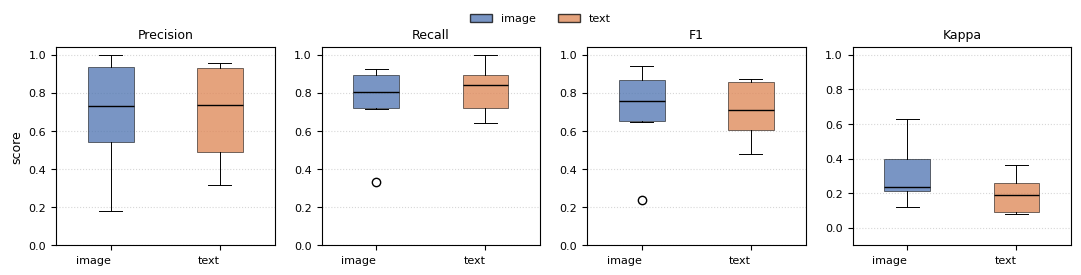

Saved figure: figures/rq1_metrics_by_representation.png


In [9]:
rep_colors = [au.REP_COLORS["image"], au.REP_COLORS["text"]]
rep_labels = ["image", "text"]
panel_specs = [
    ("Precision", au.precision, (0, 1)),
    ("Recall", au.recall, (0, 1)),
    ("F1", au.f1, (0, 1)),
    ("Kappa", None, (-0.1, 1.0)),
]

fig, axes = plt.subplots(1, 4, figsize=au.FIGSIZE_ROW_4, sharey=False)
for ax, (title, mfn, ylim) in zip(axes, panel_specs):
    if mfn is not None:
        vals = [
            au.values_by_diagram(merged[merged["Representation"] == rep], mfn)
            for rep in rep_labels
        ]
    else:
        vals = [rep_kappa["image"], rep_kappa["text"]]
    au.slim_boxplot(
        ax, vals, rep_labels, colors=rep_colors,
        title=title,
        ylabel="score" if title == "Precision" else "",
        ylim=ylim,
        panel=True,
        show_ylabel=(title == "Precision"),
        label_rotation=0,
    )

au.add_rep_legend(fig)
if not DRY_RUN:
    au.save_figure(fig, FIG_DIR / "rq1_metrics_by_representation.png")
plt.show()
if not DRY_RUN:
    print("Saved figure: figures/rq1_metrics_by_representation.png")

## 8. Export summary

The ordinal agreement table is saved always (real data). The binary summaries (overall + per representation) are saved only on a real run (not in dry-run mode).

In [10]:
# Ordinal agreement uses the real ordinal GT (independent of boundary decisions),
# so it is always saved.
ordinal_summary.to_csv(OUT_ORDINAL, index=False)
print(f"Saved (real): {OUT_ORDINAL.name}")

if DRY_RUN:
    print("DRY-RUN: binary summaries NOT saved. Fill the boundary decisions and re-run for real output.")
else:
    overall_summary.to_csv(OUT_OVERALL, index=False)
    summary.to_csv(OUT_SUMMARY)
    if not diff_df.empty:
        diff_df.to_csv(NOTEBOOK_DIR / "rq1_image_vs_text_diff.csv")
    print(f"Saved: {OUT_OVERALL.name}")
    print(f"Saved: {OUT_SUMMARY.name}")
    print("Saved: rq1_image_vs_text_diff.csv")
    print("Saved figures in:", FIG_DIR)

Saved (real): rq1_ordinal_agreement.csv
Saved: rq1_overall_summary.csv
Saved: rq1_summary.csv
Saved: rq1_image_vs_text_diff.csv
Saved figures in: C:\Users\João Luiz\Desktop\Trabalhos facul\POC\llm-architecure-assesment\research-files\analysis-csv\rq-analysis\figures
